### Práctica 2: Localización de un robot con diferentes sensores

En esta práctica vamos a trabajar en un problema muy común en la robótica: la localización de un robot móvil empleando la información de sus sensores.

Los robots móviles pueden disponer de varias fuentes de información para localizarse en su entorno:

- **Receptores GNSS** (Global Navigation Satellite System, Sistema Global de Navegación por Satélite): reciben señales de constelaciones de satélites (GPS, Galileo o GLONASS) y las utilizan para triangular su posición sobre el globo terrestre (latitud, longitud y altitud). Es el sistema más utilizado para la localización de robots en escenarios exteriores, pero no suele estar disponible en interiores. Además, en escenarios con una densidad considerable de obstáculos (por ejemplo, un valle entre montañas o una ciudad con edificios altos), se puede ver afectado por la falta de cobertura o por señales rebotadas. En la práctica, esto se traduce en medidas ruidosas y, ocasionalmente, outliers (medidas erróneas).

- **IMU** (Inertial Measurement Unit, Unidad de Medida Inercial): combina acelerómetros, giroscopios y magnetómetros para determinar la aceleración, velocidad angular y orientación del robot. La integración de estas medidas permite obtener la posición y orientación. Sin embargo, estos sistemas presentan tanto ruidos como derivas, y la integración de estos errores los hace crecer con el tiempo. En la práctica, esto se traduce en sesgos que se acumulan y hacen que la posición estimada se desvíe progresivamente de la real.

- **Odometría**: permite estimar la posición del robot a partir de las medidas de sus encoders, unos sensores que miden el desplazamiento y velocidad de sus ruedas. Fenómenos como el deslizamiento de las ruedas pueden dar lugar a derivas que separen progresivamente la posición estimada de la real. En la práctica, esto se traduce en errores de escala y ruido que también se acumulan.

Todas estas fuentes tienen sus fortalezas y debilidades:

| Sensor | Frecuencia | Precisión a corto plazo | Precisión a largo plazo | Disponibilidad |
|--------|------------|-------------------------|-------------------------|----------------|
| GNSS | Baja (1-10 Hz) | Media	| Alta | Solo exterior |
| IMU | Alta (100-200 Hz) | Alta | Baja (deriva) | Cualquiera |
| Encoders | Alta (50-100 Hz) | Alta | Baja (deriva) | Cualquiera |

Por ello, se suelen combinar para una localización más precisa e incluso reforzar con técnicas de localización en mapas. Este es el caso del algoritmo SLAM (Simultaneous Location And Mapping), que localiza al robot en un mapa conocido a partir de la información de sus sensores sobre su entorno (escáneres láser, cámaras RGBD, sensores ultrasónicos e infrarrojos...). 

El objetivo de esta práctica es fusionar las tres fuentes para obtener una estimación de la posición del robot que sea mejor que cualquiera de ellas por separado. Para ello, vamos a trabajar con datos reales de trayectorias de un robot móvil, simular las medidas de cada sensor con sus errores característicos, e implementar dos técnicas de fusión: el filtro de Kalman y el filtro de partículas.

#### Organización de los archivos:

Los archivos de la práctica se organizan de la siguiente manera:

- *practice.ipynb*: 
    - TODO: Aquí tienes que implementar los filtros y analizar su rendimiento. 
- *path_generator.ipynb*: 
    - Genera varias rutas reales del robot para probar los filtros desarrollados.
    - TODO: Aquí puedes generar tus propias rutas.
- *src/sensor_simulator.py*: 
    - Simula las medidas de los sensores a partir de las rutas reales del robot.
    - Funciones relevantes: 
        - *sim_sensors(df_gt)*: Genera las medidas de los sensores.
- src/utils.py: 
    - Contiene métodos para mostrar gráficamente los resultados de los filtros.
    - Funciones relevantes: 
        - *load_path(name)*: Carga una ruta a partir de un archivo CSV.
        - *plot_path(gt, estimates)*: Dibuja las rutas real y estimada.
        - *plot_error(gt, estimates)*: Dibuja el error de la ruta estimada frente a la real.
- src/metrics.py:
    - Contiene métodos para calcular los errores de estimación de los filtros.
    - Funciones relevantes:
        - *summary_metrics(estimate, ground_truth)*: Calcula errores RMSE, ATE y RPE.

#### Entrega de la práctica:
Entrega: Carpeta comprimida con nombre Apellido1_Apellido2_Nombre.zip

Fecha: 24/11/2026 - 23:59

Contacto: juan.roldan@uam.es

In [8]:
import numpy as np
import sys
sys.path.append('src')
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from utils import load_path, plot_path, plot_error
from sensor_simulator import SensorSimulator
from metrics import summary_metrics, rmse_posicion

### Ejercicio 1: Filtro de Kalman para GPS

Vamos a comenzar con un modelo sencillo de velocidad constante.

En este modelo, el estado del robot se representa mediante el vector: 

$$\mathbf{x} = [x,    y,    v_{x},  v_{y}]$$

La evolución del estado se describe por el siguiente modelo cinemático:

$$
\begin{aligned}
\dot{x} &= v_{x} \\
\dot{y} &= v_{y} \\
\end{aligned}
$$

Y el filtro de Kalman se aplica sobre la siguiente discretización:

$$
\begin{aligned}
x_{k+1} &= x_k + v_{xk} \Delta t \\
y_{k+1} &= y_k + v_{yk} \Delta t \\
\end{aligned}
$$

A) Implementa un filtro de Kalman que trabaje con las medidas del GPS y un modelo de velocidad constante.

1. Crea la función de predicción, que propaga el estado y la covarianza utilizando un modelo de movimiento.
2. Crea la función de actualización, que corrige el estado empleando la medida del GPS.

In [9]:
class KalmanFilterGPS:
    """
    Filtro de Kalman para GPS
    Estado: [x, y, vx, vy]
    Predicción con modelo de velocidad constante
    Actualización con medidas del GPS
    """
    def __init__(self, dt, sigma_gps=1.5):
        self.dt = dt
        self.sigma_gps = sigma_gps
        
        # Estado inicial
        self.x = np.zeros(4)  # [x, y, vx, vy]
        
        # Covarianza inicial
        self.P = np.eye(4) * 10.0
        
        # Matriz de transición
        # x_{k+1}  = x_k + vx·dt      -> fila [1, 0, dt, 0]
        # y_{k+1}  = y_k + vy·dt      -> fila [0, 1, 0, dt]
        # vx_{k+1} = vx_k             -> fila [0, 0, 1, 0]
        # vy_{k+1} = vy_k             -> fila [0, 0, 0, 1]
        self.F = np.array([
            [1, 0, dt, 0],
            [0, 1, 0, dt],
            [0, 0, 1, 0],
            [0, 0, 0, 1]
        ])
        
        # Ruido del proceso
        q = 0.1
        self.Q = q * np.array([
            [dt**3/3, 0, dt**2/2, 0],
            [0, dt**3/3, 0, dt**2/2],
            [dt**2/2, 0, dt, 0],
            [0, dt**2/2, 0, dt]
        ])
        
        # Matriz de medida
        self.H = np.array([
            [1, 0, 0, 0],
            [0, 1, 0, 0]
        ])
        
        # Ruido de medida
        self.R = np.eye(2) * sigma_gps**2
    
    def predict(self):
        """Paso de predicción"""
        self.x = self.F @ self.x 
        self.P = self.F @ self.P @ np.transpose(self.F) + self.Q
            
    def update(self, z):
        """Paso de actualización"""
        z = np.asarray(z)

        # Innovación
        y = z - self.H @ self.x

        # Covarianza de la innovación
        S = self.H @ self.P @ np.transpose(self.H) + self.R

        # Ganancia de Kalman
        K = self.P @ np.transpose(self.H) @ np.linalg.inv(S)

        # Actualización del estado
        self.x = self.x + K @ y

        # Actualización de la covarianza
        I = np.eye(self.P.shape[0])
        self.P = (I - K @ self.H) @ self.P
    
    def step(self, z_gps):
        """Paso completo"""
        self.predict()
        if z_gps is not None:
            self.update(z_gps)
        return self.x.copy()

B) Compara el error de las medidas brutas del GPS con el del filtro de Kalman. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


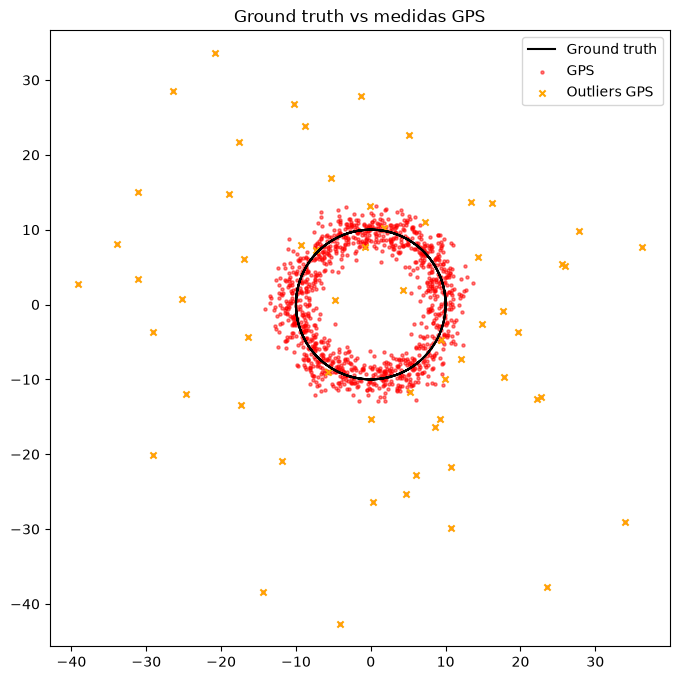

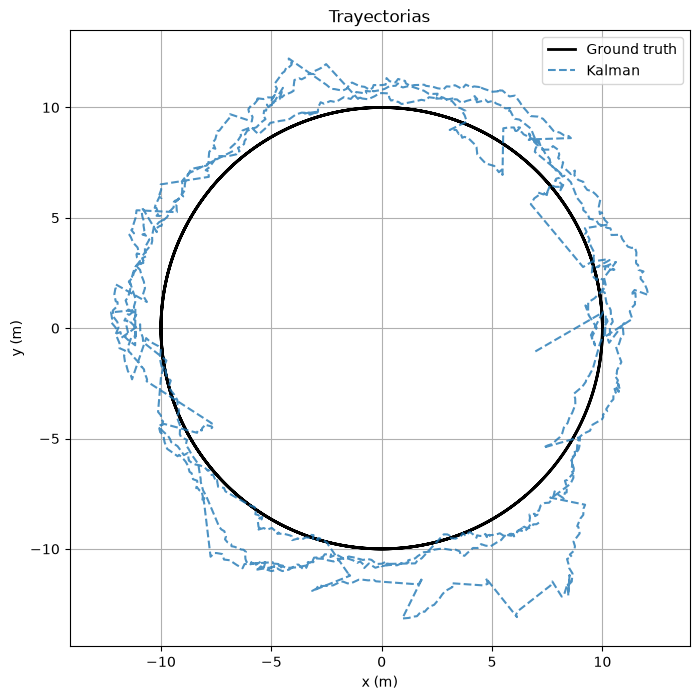

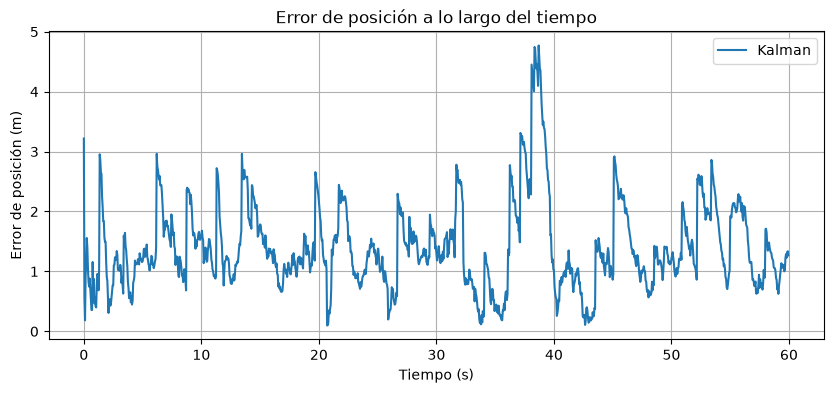

Kalman       RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m


In [10]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular') # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPS(dt=dt, sigma_gps=1.5)

estimates_kf = np.zeros((len(df_gt), 4))
for i in range(len(df_gt)):
    z = np.array([medidas['gps']['x_gps'].iloc[i], medidas['gps']['y_gps'].iloc[i]])
    estimates_kf[i] = kalman.step(z)

# 5. Representa el resultado
estimates = {'Kalman': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for name, est in estimates.items():
    m = summary_metrics(est, gt_array, name)
    print(f"{m['name']:12s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza el desempeño del filtro de Kalman. ¿El filtro mejora la señal del GPS? ¿El error es adecuado o excesivo para la tarea? ¿Qué causas puede tener este error? ¿Cómo se podría reducir?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis 

Comparamos el error de las medidas brutas del GPS con el de la estimación del filtro, separamos el efecto de los outliers, medimos el sesgo en la curva y probamos la sensibilidad al ruido de proceso $q$.

GPS bruto  RMSE=5.232 m  ATE=5.231 m  RPE=4.082 m
Kalman     RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m

Reducción del RMSE con el filtro: 70 %
Error máximo:  GPS = 51.20 m   Kalman = 4.77 m

Outliers del GPS: 59 de 1200
RMSE del GPS solo con medidas buenas : 2.14 m
RMSE del GPS solo con outliers       : 21.64 m
Error medio del Kalman cuando hay outlier : 1.94 m
Error medio del Kalman cuando no hay      : 1.37 m

Radio real del círculo: 9.98 m   radio estimado: 11.01 m
Aceleración centrípeta real: 0.90 m/s² (el modelo supone que es 0)
RMSE de la velocidad: 1.52 m/s (velocidad real ≈ 3.0 m/s)

RMSE según el valor de q:
  q = 0.001  RMSE = 6.475 m
  q = 0.01   RMSE = 3.002 m
  q = 0.1    RMSE = 1.582 m
  q = 1      RMSE = 1.606 m
  q = 10     RMSE = 2.038 m


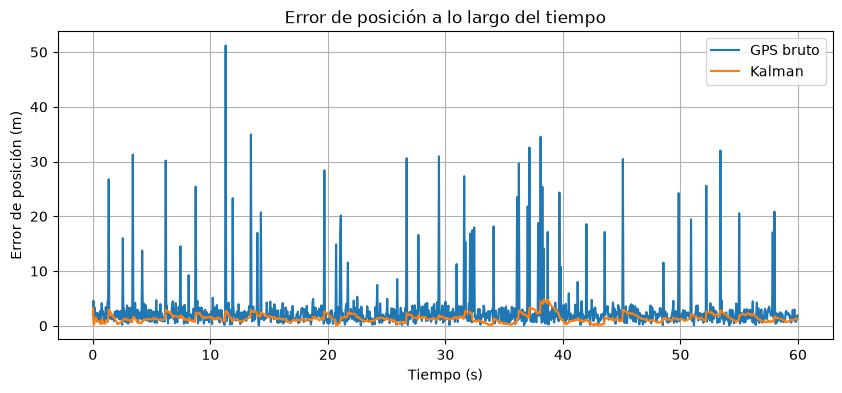

In [11]:
# --- Comparación del GPS bruto con el filtro de Kalman ---

z_gps = medidas['gps'][['x_gps', 'y_gps']].values        # medidas del GPS
es_outlier = medidas['gps']['is_outlier'].values == 1     # qué medidas son outliers de verdad

def error_posicion(estimacion):
    """Distancia (en metros) entre la posición estimada y la real en cada instante."""
    return np.linalg.norm(estimacion[:, :2] - gt_array[:, :2], axis=1)

err_gps = error_posicion(z_gps)
err_kf = error_posicion(estimates_kf)

# 1. Errores (RMSE, ATE y RPE) con summary_metrics
for nombre, est in {'GPS bruto': z_gps, 'Kalman': estimates_kf}.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:10s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

mejora = 1 - rmse_posicion(estimates_kf, gt_array) / rmse_posicion(z_gps, gt_array)
print(f"\nReducción del RMSE con el filtro: {100 * mejora:.0f} %")
print(f"Error máximo:  GPS = {err_gps.max():.2f} m   Kalman = {err_kf.max():.2f} m")

# 2. Efecto de los outliers
print(f"\nOutliers del GPS: {es_outlier.sum()} de {len(es_outlier)}")
print(f"RMSE del GPS solo con medidas buenas : {rmse_posicion(z_gps[~es_outlier], gt_array[~es_outlier]):.2f} m")
print(f"RMSE del GPS solo con outliers       : {rmse_posicion(z_gps[es_outlier], gt_array[es_outlier]):.2f} m")
print(f"Error medio del Kalman cuando hay outlier : {err_kf[es_outlier].mean():.2f} m")
print(f"Error medio del Kalman cuando no hay      : {err_kf[~es_outlier].mean():.2f} m")

# 3. Error del modelo de velocidad constante en la curva
centro = gt_array[:, :2].mean(axis=0)
radio_real = np.linalg.norm(gt_array[:, :2] - centro, axis=1).mean()
radio_estimado = np.linalg.norm(estimates_kf[:, :2] - centro, axis=1).mean()
print(f"\nRadio real del círculo: {radio_real:.2f} m   radio estimado: {radio_estimado:.2f} m")

velocidad_real = np.linalg.norm(gt_array[:, 2:], axis=1).mean()
aceleracion_centripeta = velocidad_real**2 / radio_real
print(f"Aceleración centrípeta real: {aceleracion_centripeta:.2f} m/s² (el modelo supone que es 0)")

rmse_velocidad = rmse_posicion(estimates_kf[:, 2:], gt_array[:, 2:])   # columnas [vx, vy] en lugar de [x, y]
print(f"RMSE de la velocidad: {rmse_velocidad:.2f} m/s (velocidad real ≈ {velocidad_real:.1f} m/s)")

# 4. ¿Cómo cambia el error según el ruido de proceso q? (en la clase q = 0.1)
print("\nRMSE según el valor de q:")
for q in [0.001, 0.01, 0.1, 1, 10]:
    kf_q = KalmanFilterGPS(dt=dt, sigma_gps=1.5)
    kf_q.Q = kf_q.Q / 0.1 * q              # cambiamos q manteniendo la forma de Q
    est_q = np.array([kf_q.step(z) for z in z_gps])
    print(f"  q = {q:<6} RMSE = {rmse_posicion(est_q, gt_array):.3f} m")

# 5. Gráfica del error en el tiempo
plot_error(df_gt, {'GPS bruto': z_gps, 'Kalman': estimates_kf})

#### Respuestas

**¿El filtro mejora la señal del GPS?**

Sí, como se puede ver en la gráfica del error de la posición a lo largo del tiempo, el filtro mejora mucho la señal del GPS. El RMSE de posición baja de **5.23 m** (GPS bruto) a **1.58 m** con Kalman, una reducción de casi el **70 %**. Si nos fijamos además en el error máximo la mejora es muy clara: el GPS llega tiene un error máximo de **51 m** por culpa de los outliers, mientras que el error máximo del filtro es de **4.8 m**. 

El RPE (error relativo entre muestras consecutivas) baja de 4.08 m a 0.91 m lo que indica que no hay cambios tan bruscos entre la posición de muestras consecutivas dentro de la trayectoria.

Podemos ver que con el filtro el RMSE y el ATE son casi iguales así que no hay desplazamiento. El error es por culpa de la forma (el círculo sale más grande, radio 11.0 m frente a 9.98 m, se puede ver en la representación de las trayectorias alrededor del círculo)

Si se compara solo con las medidas GPS buenas, es decir, quitando los outliers, la mejora es más no es tan grande pero aún así sigue siendo significativa. El RMSE pasa de 2.14 m a 1.58 m. 

**¿El error es adecuado o excesivo para la tarea?**

Consideramos que el error es excesivo para un robot móvil ya que recorre un círculo de 10 m de radio a 3 m/s. Un error medio de 1.4 m con picos de casi 5 m es alrededor de un 15 % del radio de la trayectoria. Esto puede provocar que según la tarea del robot sea suficiente para salirse de un carril o chocar con un obstáculo cercano. Puede valer para una tarea a no demasiado precisa como saber en qué calle está el robot, pero no para seguir una ruta o maniobrar cerca de obstáculos. Además, la velocidad estimada tiene un RMSE de 1.52 m/s para una velocidad real de 3 m/s, que es un error enorme.

**¿Qué causas puede tener este error?**

1. **Modelo de movimiento.** El filtro supone velocidad constante (movimiento rectilíneo), pero el robot gira continuamente, con una aceleración centrípeta de $v^2/R \approx 0.9$ m/s² que el modelo ignora. En cada predicción el filtro considera que el robot se mueve en línea recta, hacia fuera de la curva, y la medida solo lo corrige en parte. El círculo estimado tiene radio 11.0 m frente a los 9.98 m reales y casi todo el error es hacia afuera. Este sesgo no se reduce promediando más medidas, por eso el filtro no baja mucho del error del GPS limpio.
2. **Outliers del GPS.** Un 4.9 % de las medidas tiene un error 10 veces mayor (RMSE de 21.6 m). El filtro de Kalman supone ruido gaussiano con $\sigma = 1.5$ m y las acepta como si fueran buenas, así que cada outlier desvía la estimación. El error medio del filtro sube a 1.94 m en los instantes con outlier frente a 1.37 m en el resto.
3. **Ajuste de Q y R (compromiso).** Con $q$ pequeño el filtro confía mucho en el modelo de velocidad constante y el sesgo en la curva crece ($q=0.01$ da RMSE de 3.0 m, y $q=0.001$ de 6.5 m). Con $q$ grande sigue mejor la curva, pero se fía más de cada medida, incluidos los outliers ($q=10$ da 2.04 m). El valor usado ($q=0.1$) es el mejor de los probados, pero ningún valor de $q$ elimina a la vez el sesgo y el efecto de los outliers.
4. **Solo se mide la posición.** La velocidad no se observa directamente y se deduce de diferencias de posiciones ruidosas, lo que explica el gran error en velocidad. Ese error se propaga a la posición en el paso de predicción.

**¿Cómo se podría reducir?**

- **Rechazar outliers (gating):** descartar medidas cuya innovación sea improbable, usando la distancia de Mahalanobis $d = \sqrt{\tilde{y}^T S^{-1} \tilde{y}}$ y un umbral. Al eliminarlos, además, se puede subir $q$ para seguir mejor la curva sin miedo a que los outliers arrastren la estimación.
- **Mejorar el modelo de movimiento:** usar un modelo que represente giros, como velocidad y giro. 
- **Fusionar más sensores:** la IMU (aceleración y velocidad angular) y los encoders (velocidad) dan información directa sobre el movimiento, que es justo lo que le falta al modelo.
- **Inicializar con la primera medida GPS** en lugar de en el origen.


C) Implementa una nueva función de actualización que no pase los outliers al filtro.

In [12]:
class KalmanFilterGPSwithGating(KalmanFilterGPS):
    
    def update_gating(self, z, threshold=3.0):
        """Solo actualiza si la innovación es razonable."""
        d = 0
        # TODO: Implementar el código
        """Paso de actualización"""
        z = np.asarray(z)

        # Innovación
        y = z - self.H @ self.x

        # Covarianza de la innovación
        S = self.H @ self.P @ self.H.T + self.R

        # Distancia de Mahalanobis
        d = np.sqrt(y @ np.linalg.inv(S) @ y)


        if d < threshold:
            self.update(z)
    
    def step_gating(self, z_gps):
        """Paso completo"""
        self.predict()
        if z_gps is not None:
            self.update_gating(z_gps)
        return self.x.copy()

D) Compara el error del filtro de Kalman antes y después del gating. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


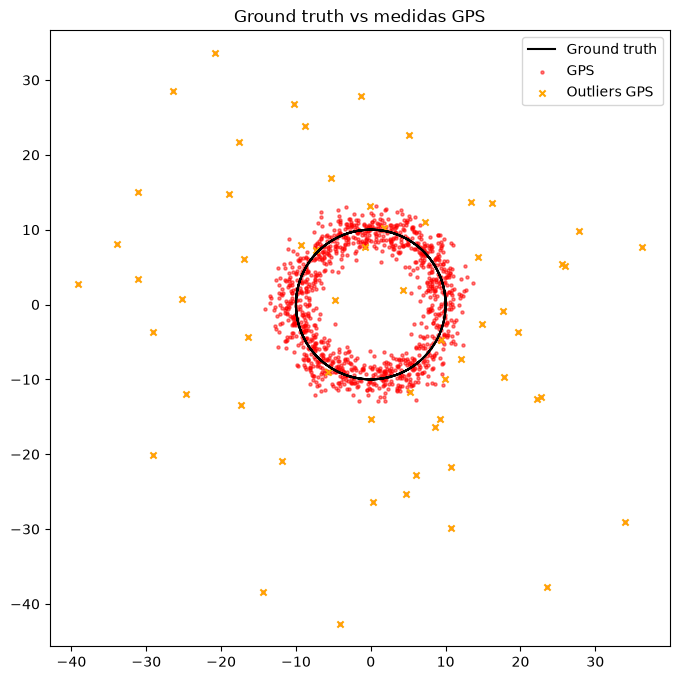

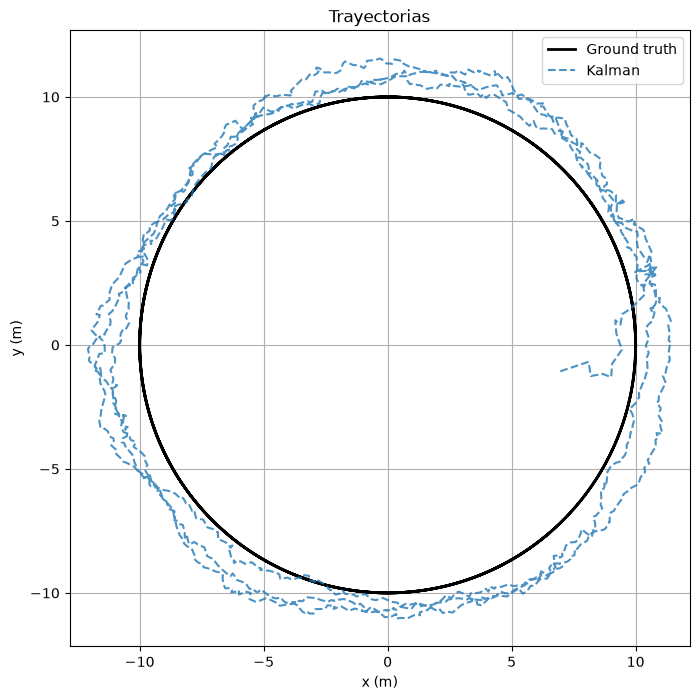

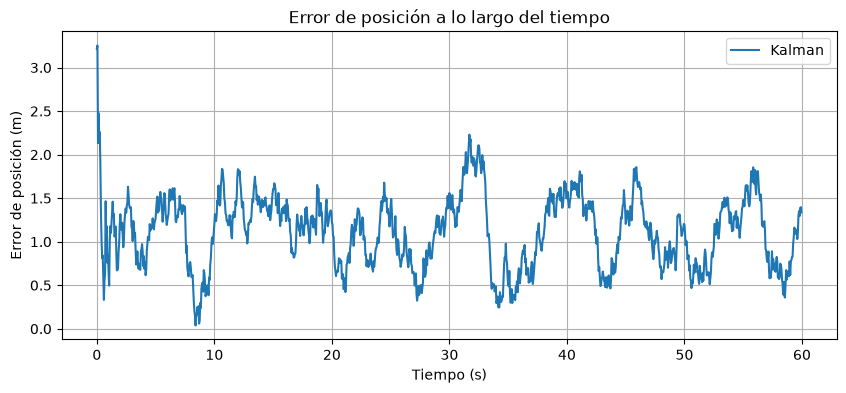

Kalman       RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m


In [13]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular') # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)

estimates_kf = np.zeros((len(df_gt), 4))
for i in range(len(df_gt)):
    z = np.array([medidas['gps']['x_gps'].iloc[i], medidas['gps']['y_gps'].iloc[i]])
    estimates_kf[i] = kalman.step_gating(z)

# 5. Representa el resultado
estimates = {'Kalman': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for name, est in estimates.items():
    m = summary_metrics(est, gt_array, name)
    print(f"{m['name']:12s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza la mejoría del filtro de Kalman. ¿Cuánto ha decrecido el error al filtrar los outliers? ¿El error es adecuado o excesivo para la tarea? ¿Qué causas puede tener este error? ¿Cómo se podría seguir reduciendo?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis

Ejecutamos el filtro sin gating y con gating sobre las mismas medidas, comparamos sus errores y vemos qué medidas ha rechazado el gating.

GPS bruto          RMSE=5.232 m  ATE=5.231 m  RPE=4.082 m
Kalman sin gating  RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m
Kalman con gating  RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m

Mejora del RMSE por el gating: 25 %

¿Qué medidas ha rechazado el gating?
  Outliers reales           : 59
  Outliers rechazados       : 56
  Medidas buenas rechazadas : 28

Radio real del círculo: 9.98 m   radio estimado con gating: 10.86 m
Kalman con gating y q=1: RMSE = 0.820 m


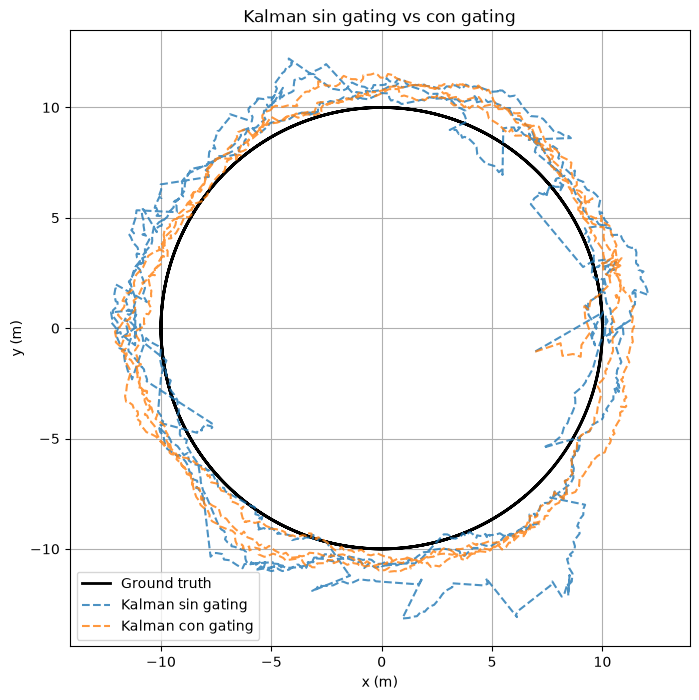

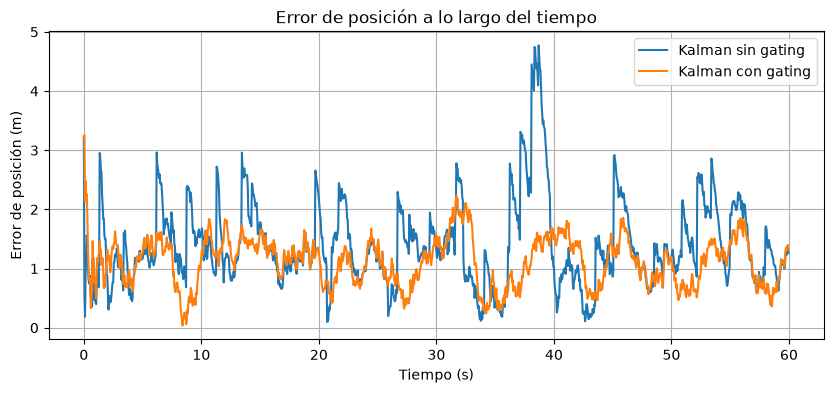

In [14]:
# --- Comparación del filtro de Kalman sin gating y con gating ---

z_gps = medidas['gps'][['x_gps', 'y_gps']].values        # medidas del GPS
es_outlier = medidas['gps']['is_outlier'].values == 1     # qué medidas son outliers de verdad

# 1. Filtro SIN gating
kf_sin = KalmanFilterGPS(dt=dt, sigma_gps=1.5)
est_sin = np.array([kf_sin.step(z) for z in z_gps])

# 2. Filtro CON gating (guardamos además qué medidas rechaza)
kf_con = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)
est_con = []
rechazada = []
for z in z_gps:
    kf_con.predict()
    estado_antes = kf_con.x.copy()
    kf_con.update_gating(z)
    rechazada.append(np.array_equal(kf_con.x, estado_antes))  # si el estado no cambia, la medida se rechazó
    est_con.append(kf_con.x.copy())
est_con = np.array(est_con)
rechazada = np.array(rechazada)

# 3. Errores (RMSE, ATE y RPE) con summary_metrics
estimaciones = {'GPS bruto': z_gps, 'Kalman sin gating': est_sin, 'Kalman con gating': est_con}
metricas = {}
for nombre, est in estimaciones.items():
    metricas[nombre] = summary_metrics(est, gt_array, nombre)
    m = metricas[nombre]
    print(f"{m['name']:18s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

mejora = 1 - metricas['Kalman con gating']['rmse'] / metricas['Kalman sin gating']['rmse']
print(f"\nMejora del RMSE por el gating: {100 * mejora:.0f} %")

print("\n¿Qué medidas ha rechazado el gating?")
print(f"  Outliers reales           : {es_outlier.sum()}")
print(f"  Outliers rechazados       : {(rechazada & es_outlier).sum()}")
print(f"  Medidas buenas rechazadas : {(rechazada & ~es_outlier).sum()}")

# 4. ¿Sigue habiendo error por el modelo de velocidad constante en la curva?
centro = gt_array[:, :2].mean(axis=0)
radio_real = np.linalg.norm(gt_array[:, :2] - centro, axis=1).mean()
radio_est = np.linalg.norm(est_con[:, :2] - centro, axis=1).mean()
print(f"\nRadio real del círculo: {radio_real:.2f} m   radio estimado con gating: {radio_est:.2f} m")

# 5. Prueba: con los outliers ya filtrados, podemos subir el ruido de proceso q (de 0.1 a 1)
kf_q = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)
kf_q.Q = kf_q.Q * 10
est_q = np.array([kf_q.step_gating(z) for z in z_gps])
print(f"Kalman con gating y q=1: RMSE = {summary_metrics(est_q, gt_array)['rmse']:.3f} m")

# 6. Gráficas: trayectorias y error en el tiempo
plot_path(df_gt, {'Kalman sin gating': est_sin, 'Kalman con gating': est_con},
          title='Kalman sin gating vs con gating')
plot_error(df_gt, {'Kalman sin gating': est_sin, 'Kalman con gating': est_con})

#### Respuestas

**¿Cuánto ha decrecido el error al filtrar los outliers?**

El RMSE baja de **1.58 m** (Kalman sin gating) a **1.19 m** (con gating), es decir, un **25 % menos**. El RPE se reduce a la mitad, de 0.91 m a 0.43 m se suaviza aún más la trayectoria estimada. Respecto al GPS bruto (5.23 m), el error total se ha reducido en un 77 %.

Si se observa la gráfica de error a lo largo del tiempo se puede ver que sin gating, cada outlier produce un pico de error porque el filtro se cree la medida errónea y se desplaza hacia ella. Con gating esos picos desaparecen.

El gating funciona bien: de los **59 outliers** reales rechaza **56**. A cambio, también descarta **28 medidas buenas** (un 2 % del total) pero perder unas pocas medidas buenas no afecta tanto a los resultados como dejar pasar un outlier.

**¿El error es adecuado o excesivo para la tarea?**

Ha mejorado, pero creemos que sigue siendo un poco alto para un robot móvil. Por la misma razón explicada antes, funcionaría muy bien para saber por dónde va el robot, pero no para moverse con precisión cerca de paredes u obstáculos.

**¿Qué causas puede tener este error?**

- **El modelo de velocidad constante no sirve bien para curvas.** El filtro supone que el robot va en línea recta, pero en realidad está girando todo el rato. Mismo error indicado en el apartado anterior que el gating no ha podido corregir.
- **El valor de $q$ es bajo.** Ahora que hay pocos outliers al haber implementado el gating, con $q = 0.1$ el filtro confía mucho en su modelo de línea recta y tarda en corregirse en la curva. 
- **Ruido normal del GPS** ($\sigma = 1.5$ m) y algún **outlier pequeño** que pasa el gating (3 de 59).
- **Solo medimos la posición.** La velocidad se deduce de posiciones ruidosas, así que se estima mal. También indicado anteriormente.

**¿Cómo se podría seguir reduciendo?**

- **Subir $q$ ahora que los outliers están filtrados.** Con $q = 1$ el filtro sigue mejor la curva y el RMSE baja a **0.82 m**. El gating es precisamente lo que permite hacer esto sin que los outliers desvíen la estimación.
- **Usar un modelo que incluya giros**, con estado $[x, y, \theta, v, \omega]$, para que la predicción siga la curva en lugar de salirse de ella.
- **Añadir más sensores:** la IMU y los encoders miden directamente la aceleración, la velocidad y el giro, justo la información que le falta al modelo. 
- **Ajustar el umbral del gating** para encontrar el mejor equilibrio entre rechazar outliers y no descartar medidas buenas.

### Ejercicio 2: Filtro de Kalman con GPS, IMU y Encoders 

Ahora vamos a pasar a un modelo de aceleración constante.

En este modelo, el estado del robot se representa mediante el vector: 

$$\mathbf{x} = [x,    y,  \theta, v,  \omega]$$

La evolución del estado se describe por el siguiente modelo cinemático:

$$
\begin{aligned}
\dot{x} &= v \cos\theta \\
\dot{y} &= v \sin\theta \\
\dot{\theta} &= \omega \\
\dot{v} &= a \\
\dot{\omega} &= \alpha
\end{aligned}
$$

Y el filtro de Kalman se aplica sobre la siguiente discretización:

$$
\begin{aligned}
x_{k+1} &= x_k + v_k \cos\theta_k \, \Delta t + \tfrac{1}{2} a_k \cos\theta_k \, \Delta t^2 \\
y_{k+1} &= y_k + v_k \sin\theta_k \, \Delta t + \tfrac{1}{2} a_k \sin\theta_k \, \Delta t^2 \\
\theta_{k+1} &= \theta_k + \omega_k \, \Delta t + \tfrac{1}{2} \alpha_k \, \Delta t^2 \\
v_{k+1} &= v_k + a_k \, \Delta t \\
\omega_{k+1} &= \omega_k + \alpha_k \, \Delta t
\end{aligned}
$$

Los sensores aportan las siguientes medidas para el nuevo modelo:

- GPS: 
    - Posición $[x, y]$: Se puede usar en el paso de actualización como medida directa de la posición.
- IMU: 
    - Aceleración $a_{imu}$: Se puede usar en el paso de predicción para propagar la velocidad y la posición. La medida viene contaminada por un sesgo $b_a$ y un ruido gaussiano $v_a$.
    - Velocidad angular $\omega_{imu}$: Se puede usar en el paso de predicción para propagar la orientación. También tiene un sesgo $b_\omega$ y un ruido $v_{\omega}$.
- Encoders:
    - Desplazamiento $\Delta s_{enc}$: Se puede utilizar para calcular la velocidad en el paso de actualización $v_{enc}= \tfrac{\Delta s_{enc}}{ \Delta t}$
    - Giro $\Delta \theta_{enc}$: Se puede utilizar para calcular la velocidad angular en el paso de actualización $\omega_{enc}= \tfrac{\Delta \theta_{enc}}{\Delta t}$

    A) Implementa un filtro de Kalman que trabaje con las medidas del GPS, la IMU y los Encoders.

In [18]:
class KalmanFilterGPSIMUEncoders:
    """
    Filtro de Kalman para GPS, IMU y Encoders
    Estado: [x, y, theta, v, omega]
    Predicción con modelo de aceleración constante
    Actualización con medidas del GPS, predicción con IMU y Encoders
    """
    def __init__(self, dt, sigma_gps=1.5, sigma_imu_a=0.1, sigma_imu_w=0.02,
                 sigma_enc_v=0.05, sigma_enc_w=0.02):
        self.dt = dt
        self.x = np.zeros(5)  # [x, y, theta, v, omega]
        self.P = np.eye(5) * 1.0
        self.P[0, 0] = 5.0   # posición: más incertidumbre inicial
        self.P[1, 1] = 5.0
        self.P[2, 2] = 1.0   # orientación
        self.P[3, 3] = 2.0   # velocidad
        self.P[4, 4] = 0.5   # velocidad angular

        # Ruido del proceso
        self.Q = np.diag([
            0.01, 0.01, 0.001, 0.05, 0.01
        ])

        # Medidas
        self.H_gps = np.array([
            [1, 0, 0, 0, 0],
            [0, 1, 0, 0, 0]
        ])
        self.R_gps = np.eye(2) * sigma_gps**2

        self.H_enc = np.array([
            [0, 0, 0, 1, 0],
            [0, 0, 0, 0, 1]
        ])
        self.R_enc = np.diag([sigma_enc_v**2, sigma_enc_w**2])

    def normalize_angle(self):
        """Normaliza theta a [-pi, pi]."""
        self.x[2] = (self.x[2] + np.pi) % (2 * np.pi) - np.pi

    def predict(self, a_imu, omega_imu):
        """Predicción usando medidas de la IMU."""
        # TODO: Implementar

        pass 
    
    def update_gps_gating(self, z_gps, umbral=3.0):
        """Corrección con posición GPS."""
        d = 0
        # TODO: Implementar 
        
        if d > umbral:
            return False

        return True

    def update_encoders(self, v_enc, omega_enc):
        """Corrección con medidas de velocidad de los encoders."""
        # TODO: Implementar

        pass

    def step(self, a_imu, omega_imu, z_gps=None, z_enc=None):
        """Un paso completo: predicción + actualizaciones disponibles."""
        self.predecir(a_imu, omega_imu)
        if z_gps is not None:
            self.update_gps_gating(z_gps)
        if z_enc is not None:
            self.update_encoders(z_enc[0], z_enc[1])
        return self.x.copy()

B) Analiza el rendimiento de este nuevo filtro de Kalman frente al anterior. 

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


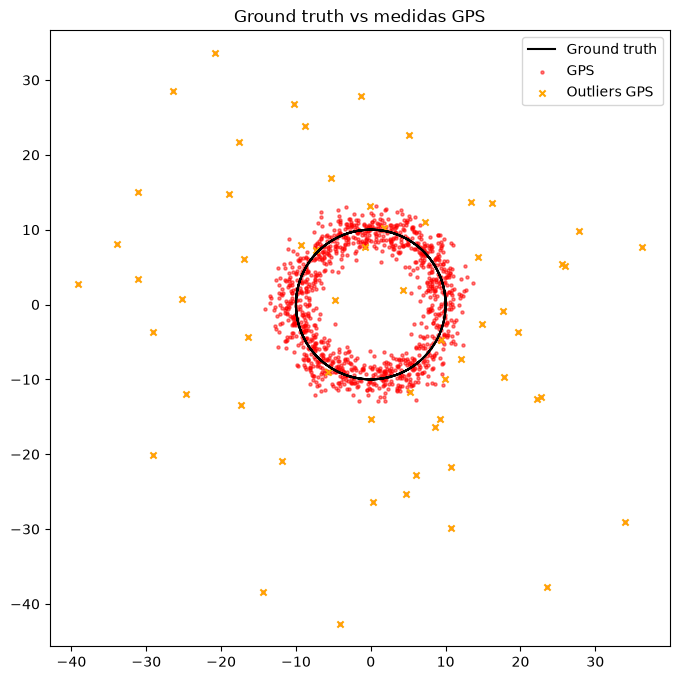

Medidas GPS descartadas por gating: 0 / 1200


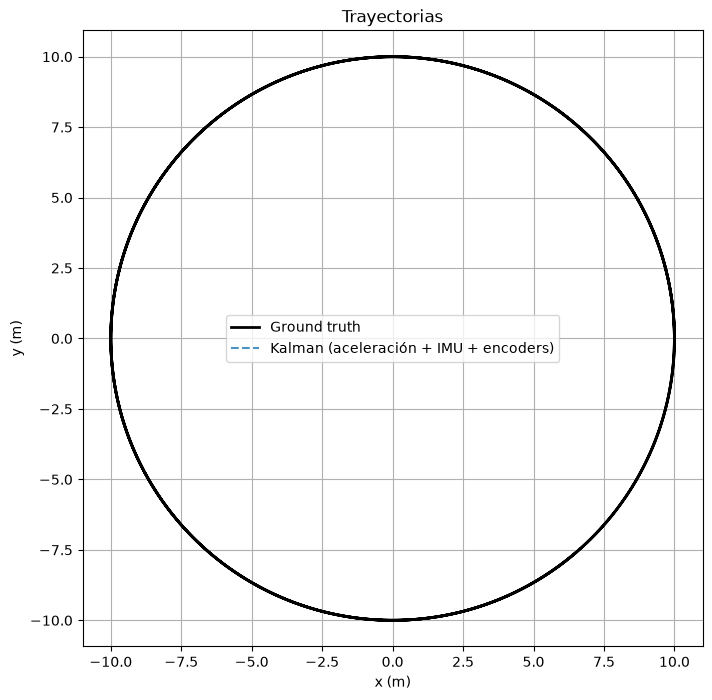

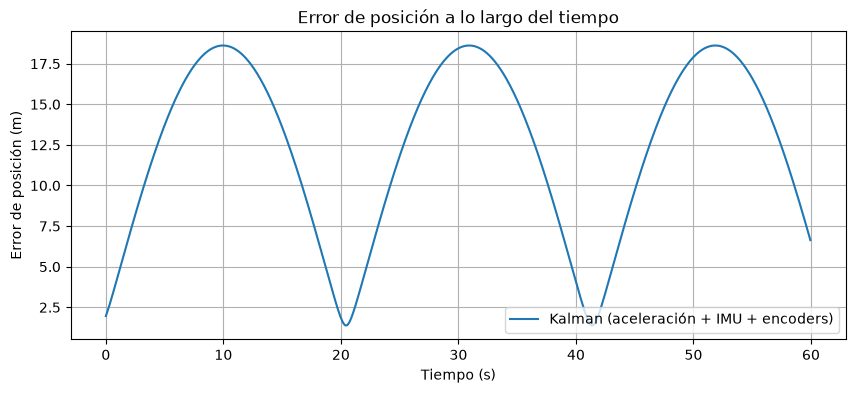

Kalman (aceleración + IMU + encoders)    RMSE=13.486 m  ATE=9.990 m  RPE=1.499 m


In [13]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular')  # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de Kalman con GPS, IMU y encoders
dt = 1.0 / meta['frecuencia_hz']
kalman = KalmanFilterGPSIMUEncoders(
    dt=dt,
    sigma_gps=1.5,
    sigma_imu_a=0.1,
    sigma_imu_w=0.02,
    sigma_enc_v=0.05,
    sigma_enc_w=0.02
)

# Inicializar el estado con la primera medida GPS
kalman.x = np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # theta inicial
    0.0,   # v inicial
    0.0    # omega inicial
])

kalman.P = np.diag([4.0, 4.0, 1.0, 1.0, 0.5])

estimates_kf = np.zeros((len(df_gt), 5))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medidas de la IMU
    a_imu = medidas['imu']['ax_imu'].iloc[i]
    omega_imu = medidas['imu']['omega_imu'].iloc[i]

    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])

    # Medidas de los encoders (convertidas a velocidad)
    v_enc = medidas['encoders']['ds_enc'].iloc[i] / dt
    omega_enc = medidas['encoders']['dtheta_enc'].iloc[i] / dt
    z_enc = (v_enc, omega_enc)

    # Paso del filtro: predicción + gating GPS + actualización encoders
    kalman.predict(a_imu, omega_imu)
    updated = kalman.update_gps_gating(z_gps, umbral=3.0)
    if not updated:
        n_descartadas += 1
    kalman.update_encoders(v_enc, omega_enc)

    estimates_kf[i] = kalman.x.copy()

print(f"Medidas GPS descartadas por gating: {n_descartadas} / {len(df_gt)}")

# 5. Representa el resultado
estimates = {'Kalman (aceleración + IMU + encoders)': estimates_kf}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
# Nota: el ground truth solo tiene [x, y, vx, vy]; comparamos las dos primeras columnas.
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for nombre, est in estimates.items():
    m = summary_metrics(est[:, :4], gt_array, nombre)  # usamos [x, y, v, omega] → ajustar según métrica
    print(f"{m['name']:40s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza la mejoría del filtro de Kalman. ¿Cuánto ha decrecido el error al integrar medidas de otros sensores? ¿El error es adecuado o excesivo para la tarea? ¿Cómo crees que se podría seguir reduciendo?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

### Ejercicio 3: Filtro de Partículas

Implementar un filtro de Partículas para fusionar las medidas del GPS, la IMU y los encoders, obteniendo una localización precisa del robot. 

1. Crea la función de inicialización, que distribuye las partículas alrededor del estado inicial
2. Crea la función de predicción, que propaga las partículas según el modelo y añadiendo ruido
3. Crea la función de actualización, que actualiza los pesos según la verosimilitud de la medida del GPS
4. Crea la función de remuestreo, que filtra las partículas según sus pesos.

In [15]:
class ParticleFilter:
    """
    Filtro de partículas para fusión de GPS + IMU + encoders
    Estado: [x, y, vx, vy]
    """
    def __init__(self, dt, n_particulas=500, sigma_gps=1.5):
        self.dt = dt
        self.N = n_particulas
        self.sigma_gps = sigma_gps
        self.rng = np.random.default_rng(0)
        
        self.particulas = np.zeros((self.N, 4))
        self.pesos = np.ones(self.N) / self.N
    
    def initialize(self, x0):
        """Inicializa partículas alrededor de x0"""
        self.particulas = x0 + self.rng.normal(0, self.sigma_gps, size=(self.N, 4))
    
    def predict(self, a_imu=None, omega_imu=None):
        """Propaga partículas con el modelo de movimiento + ruido"""
        x, y, vx, vy = self.particulas.T

        # Actualizamos la velocidad con la aceleración de la IMU
        if a_imu is not None:
            vx += a_imu[0] * self.dt
            vy += a_imu[1] * self.dt

        # Actualizamos la posición con la velocidad
        x += vx * self.dt
        y += vy * self.dt

        # Añadimos ruido de proceso cogiendo unos valores arbitrarios
        x += self.rng.normal(0, 0.1, size=self.N)
        y += self.rng.normal(0, 0.1, size=self.N)
        vx += self.rng.normal(0, 0.05, size=self.N)
        vy += self.rng.normal(0, 0.05, size=self.N)
        self.particulas = np.vstack((x, y, vx, vy)).T       
    
    def update(self, z_gps):
        """Actualiza pesos según verosimilitud de la medida GPS"""
        z_gps = np.asarray(z_gps)

        # Calculamos la distancia euclídea entre cada partícula y la medida GPS
        distancias = np.linalg.norm(self.particulas[:, :2] - z_gps[:2], axis=1)

        # Calculamos la verosimilitud usando una distribución normal
        self.pesos = np.exp(-0.5 * (distancias / self.sigma_gps)**2)
        self.pesos += 1e-300  # Evitamos pesos nulos
        self.pesos /= np.sum(self.pesos)  # Normalizamos los pesos
    
    def resampling(self):
        """Resampling sistemático"""
        indices = np.zeros(self.N, dtype=int)
        cumsum = np.cumsum(self.pesos)
        step = 1.0 / self.N
        u0 = self.rng.uniform(0, step)
        j = 0
        for i in range(self.N):
            u = u0 + i * step
            while u > cumsum[j]:
                j += 1
            indices[i] = j
        self.particulas = self.particulas[indices]
        self.pesos.fill(1.0 / self.N)
    
    def estimate(self):
        """Devuelve la media ponderada de las partículas"""
        return np.average(self.particulas, axis=0, weights=self.pesos)
    
    def step(self, z_gps, a_imu=None):
        self.predict(a_imu)
        if z_gps is not None:
            self.update(z_gps)
            self.resampling()
        return self.estimate()

    def step_with_gating(self, z_gps, a_imu=None, umbral=5.0):
        self.predict(a_imu)
        if z_gps is not None:
            # Gating euclídeo: descartar si la medida está muy lejos de la estimación
            estimacion = self.estimate()
            distancia = np.linalg.norm(z_gps[:2] - estimacion[:2])
            if distancia < umbral:
                self.update(z_gps)
                self.resampling()
        return self.estimate()

B) Analiza el rendimiento del filtro de partículas con y sin gating.

Trayectoria: trayectoria_circular, 1200 muestras, 20.0 Hz


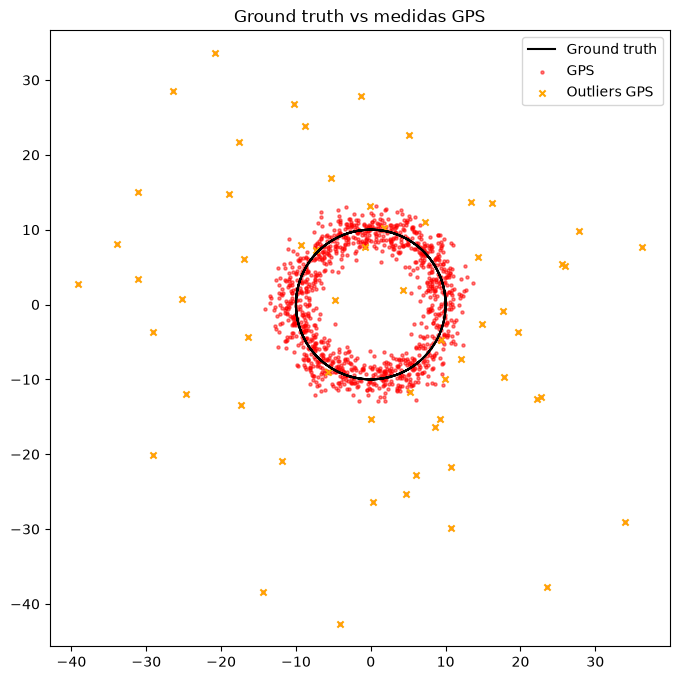

Muestras procesadas: 1200
Muestras procesadas: 1200


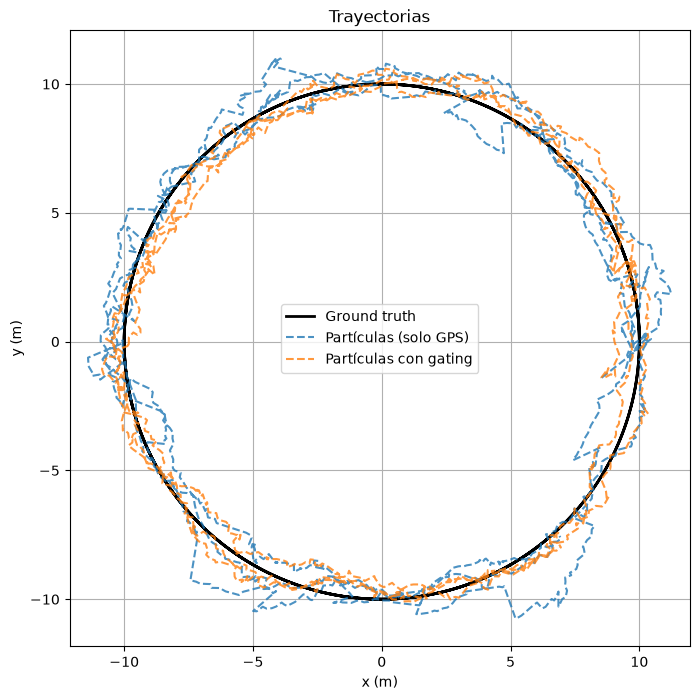

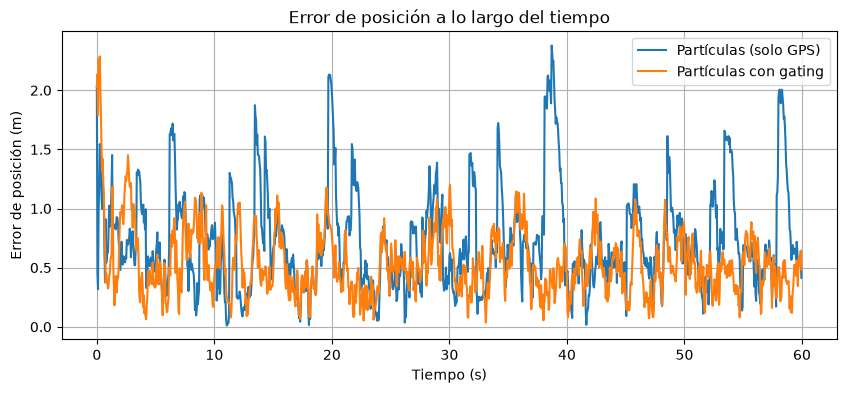

Partículas (solo GPS)          RMSE=0.846 m  ATE=0.844 m  RPE=0.665 m
Partículas con gating          RMSE=0.604 m  ATE=0.596 m  RPE=0.436 m


In [16]:
# 1. Carga una trayectoria
df_gt, meta = load_path('trayectoria_circular')  # TODO: Elige tu propia trayectoria

print(f"Trayectoria: {meta['nombre']}, {len(df_gt)} muestras, {meta['frecuencia_hz']} Hz")
df_gt.head()

# 2. Genera las medidas de los sensores del robot
sim = SensorSimulator(seed=42)
medidas = sim.sim_sensors(df_gt)

# 3. Visualiza la trayectoria real y las medidas del GPS
plt.figure(figsize=(8, 8))
plt.plot(df_gt['x'], df_gt['y'], 'k-', label='Ground truth')
plt.scatter(medidas['gps']['x_gps'], medidas['gps']['y_gps'],
            c='red', s=5, alpha=0.5, label='GPS')
out = medidas['gps']['is_outlier'] == 1
plt.scatter(medidas['gps'].loc[out, 'x_gps'],
            medidas['gps'].loc[out, 'y_gps'],
            c='orange', s=20, marker='x', label='Outliers GPS')
plt.axis('equal')
plt.legend()
plt.title('Ground truth vs medidas GPS')
plt.show()

# 4. Ejecuta el filtro de partículas sin gating
dt = 1.0 / meta['frecuencia_hz']

pf = ParticleFilter(
    dt=dt,
    n_particulas=500,
    sigma_gps=1.5
)

# Inicializar las partículas alrededor de la primera medida GPS
pf.initialize(np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # vx inicial
    0.0    # vy inicial
]))

estimates_pf = np.zeros((len(df_gt), 4))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])
    a_imu = np.array([medidas['imu']['ax_imu'].iloc[i], medidas['imu']['ay_imu'].iloc[i]])

    # Paso del filtro de partículas
    estimates_pf[i] = pf.step(z_gps, a_imu)

print(f"Muestras procesadas: {len(df_gt)}")

# 5. Ejecuta el filtro de partículas sin gating
dt = 1.0 / meta['frecuencia_hz']

pf = ParticleFilter(
    dt=dt,
    n_particulas=500,
    sigma_gps=1.5
)

# Inicializar las partículas alrededor de la primera medida GPS
pf.initialize(np.array([
    medidas['gps']['x_gps'].iloc[0],
    medidas['gps']['y_gps'].iloc[0],
    0.0,   # vx inicial
    0.0    # vy inicial
]))

estimates_pf_gating = np.zeros((len(df_gt), 4))
n_descartadas = 0

for i in range(len(df_gt)):
    # Medida GPS
    z_gps = np.array([
        medidas['gps']['x_gps'].iloc[i],
        medidas['gps']['y_gps'].iloc[i]
    ])
    a_imu = np.array([medidas['imu']['ax_imu'].iloc[i], medidas['imu']['ay_imu'].iloc[i]])

    # Paso del filtro de partículas
    estimates_pf_gating[i] = pf.step_with_gating(z_gps, a_imu)

print(f"Muestras procesadas: {len(df_gt)}")

# 5. Representa el resultado
estimates = {'Partículas (solo GPS)': estimates_pf, 'Partículas con gating': estimates_pf_gating}
plot_path(df_gt, estimates)
plot_error(df_gt, estimates)

# 6. Calcula el error
gt_array = df_gt[['x', 'y', 'vx', 'vy']].values
for nombre, est in estimates.items():
    m = summary_metrics(est, gt_array, nombre)
    print(f"{m['name']:30s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

**TODO: Analiza los resultados del filtro de partículas. ¿El gating es interesante? ¿Cuál es su rendimiento en comparación con el filtro de Kalman? ¿Por qué crees que ocurre esto?**

Nota: Puedes añadir las celdas de Markdown y Code que necesites para responder a las preguntas.

#### Análisis

Medimos cuánto mejora el gating, qué medidas rechaza, qué pasa si el filtro no usa la IMU y comparamos el filtro de partículas con los filtros de Kalman de los ejercicios anteriores.

Filtro de partículas (GPS + IMU):
  Sin gating                           RMSE=0.846 m  ATE=0.844 m  RPE=0.665 m
  Con gating                           RMSE=0.604 m  ATE=0.596 m  RPE=0.436 m

  Outliers rechazados: 56 de 59
  Medidas buenas rechazadas: 2

Filtro de partículas SIN IMU (solo GPS):
  Sin gating                           RMSE=8.393 m  ATE=6.294 m  RPE=0.946 m
  Con gating                           RMSE=128.204 m  ATE=66.151 m  RPE=2.225 m

Comparación de todos los filtros:
  Kalman (solo GPS)                    RMSE=1.582 m  ATE=1.579 m  RPE=0.913 m
  Kalman con gating (solo GPS)         RMSE=1.189 m  ATE=1.186 m  RPE=0.431 m
  EKF (GPS + IMU + encoders)           RMSE=13.486 m  ATE=9.990 m  RPE=1.499 m
  Partículas (GPS + IMU)               RMSE=0.846 m  ATE=0.844 m  RPE=0.665 m
  Partículas con gating (GPS + IMU)    RMSE=0.604 m  ATE=0.596 m  RPE=0.436 m


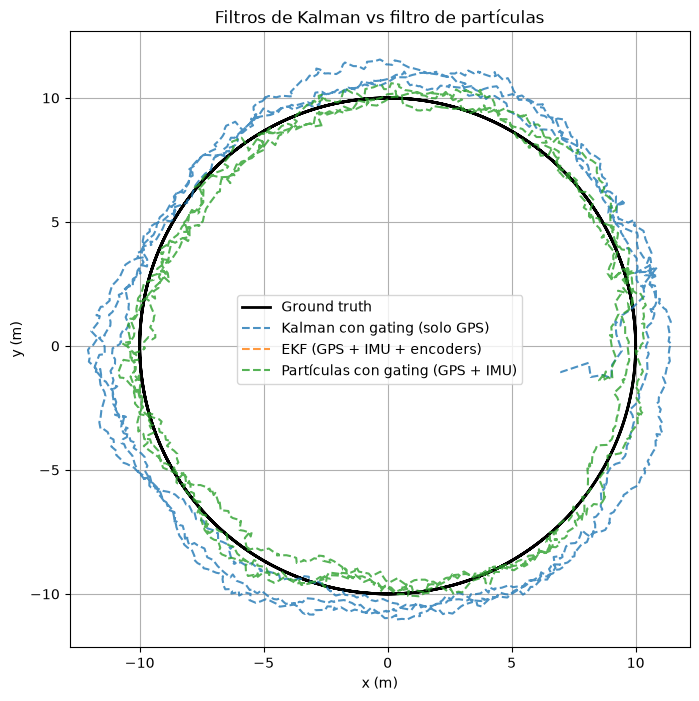

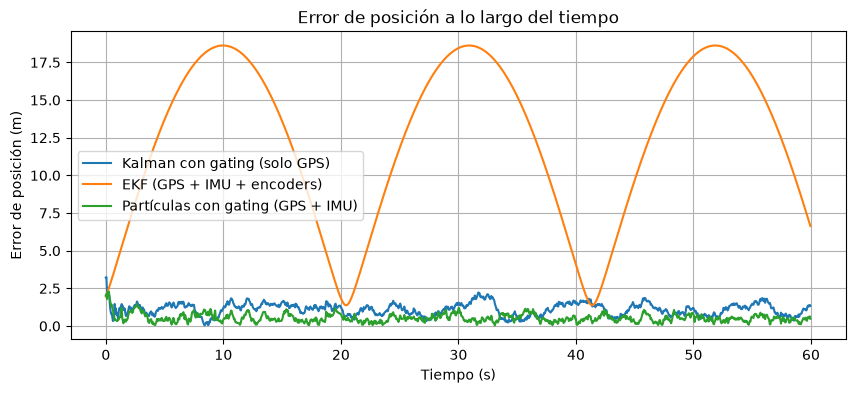

In [19]:
# --- Análisis del filtro de partículas y comparación con los filtros de Kalman ---

z_gps = medidas['gps'][['x_gps', 'y_gps']].values                # medidas del GPS
a_imu = medidas['imu'][['ax_imu', 'ay_imu']].values               # aceleraciones de la IMU
es_outlier = medidas['gps']['is_outlier'].values == 1             # qué medidas son outliers de verdad
x0 = np.array([z_gps[0, 0], z_gps[0, 1], 0.0, 0.0])               # estado inicial: primera medida GPS

def imprimir_metricas(estimaciones):
    """Muestra RMSE, ATE y RPE de cada estimación usando summary_metrics."""
    for nombre, est in estimaciones.items():
        m = summary_metrics(est, gt_array, nombre)
        print(f"  {m['name']:36s} RMSE={m['rmse']:.3f} m  ATE={m['ate']:.3f} m  RPE={m['rpe']:.3f} m")

# 1. Filtro de partículas sin y con gating (los resultados de la celda anterior)
print("Filtro de partículas (GPS + IMU):")
imprimir_metricas({'Sin gating': estimates_pf, 'Con gating': estimates_pf_gating})

# 2. ¿Qué medidas rechaza el gating?
pf = ParticleFilter(dt=dt, n_particulas=500, sigma_gps=1.5)
pf.initialize(x0)
rechazada = []
for i in range(len(z_gps)):
    pf.predict(a_imu[i])
    distancia = np.linalg.norm(z_gps[i] - pf.estimate()[:2])
    if distancia < 5.0:                    # mismo umbral que step_with_gating
        pf.update(z_gps[i])
        pf.resampling()
    rechazada.append(distancia >= 5.0)
rechazada = np.array(rechazada)
print(f"\n  Outliers rechazados: {(rechazada & es_outlier).sum()} de {es_outlier.sum()}")
print(f"  Medidas buenas rechazadas: {(rechazada & ~es_outlier).sum()}")

# 3. Riesgo del gating: ¿qué pasa si el filtro NO usa la IMU y se pierde?
pf_sin_imu = ParticleFilter(dt=dt, n_particulas=500, sigma_gps=1.5)
pf_sin_imu.initialize(x0)
est_sin_imu = np.array([pf_sin_imu.step(z) for z in z_gps])

pf_sin_imu_gating = ParticleFilter(dt=dt, n_particulas=500, sigma_gps=1.5)
pf_sin_imu_gating.initialize(x0)
est_sin_imu_gating = np.array([pf_sin_imu_gating.step_with_gating(z) for z in z_gps])

print("\nFiltro de partículas SIN IMU (solo GPS):")
imprimir_metricas({'Sin gating': est_sin_imu, 'Con gating': est_sin_imu_gating})

# 4. Comparación con los filtros de Kalman de los ejercicios anteriores
kf = KalmanFilterGPS(dt=dt, sigma_gps=1.5)
est_kf = np.array([kf.step(z) for z in z_gps])

kf_gating = KalmanFilterGPSwithGating(dt=dt, sigma_gps=1.5)
est_kf_gating = np.array([kf_gating.step_gating(z) for z in z_gps])

ekf = KalmanFilterGPSIMUEncoders(dt=dt)
ekf.x = np.array([z_gps[0, 0], z_gps[0, 1], 0.0, 0.0, 0.0])
ekf.P = np.diag([4.0, 4.0, 1.0, 1.0, 0.5])
est_ekf = []
for i in range(len(z_gps)):
    ekf.predict(medidas['imu']['ax_imu'].iloc[i], medidas['imu']['omega_imu'].iloc[i])
    ekf.update_gps_gating(z_gps[i], umbral=3.0)
    ekf.update_encoders(medidas['encoders']['ds_enc'].iloc[i] / dt,
                        medidas['encoders']['dtheta_enc'].iloc[i] / dt)
    est_ekf.append(ekf.x.copy())
est_ekf = np.array(est_ekf)

print("\nComparación de todos los filtros:")
imprimir_metricas({
    'Kalman (solo GPS)':                 est_kf,
    'Kalman con gating (solo GPS)':      est_kf_gating,
    'EKF (GPS + IMU + encoders)':        est_ekf,
    'Partículas (GPS + IMU)':            estimates_pf,
    'Partículas con gating (GPS + IMU)': estimates_pf_gating,
})

# 5. Gráficas de los mejores filtros: trayectorias y error en el tiempo
mejores = {
    'Kalman con gating (solo GPS)':      est_kf_gating,
    'EKF (GPS + IMU + encoders)':        est_ekf,
    'Partículas con gating (GPS + IMU)': estimates_pf_gating,
}
plot_path(df_gt, mejores, title='Filtros de Kalman vs filtro de partículas')
plot_error(df_gt, mejores)

#### Respuestas

**¿El gating es interesante?**

Sí, aunque tiene ventajas y desventajas.

- **Ventaja:** el RMSE baja de **0.85 m** a **0.60 m**. El gating rechaza **56 de los 59 outliers** y solo descarta **2 medidas buenas**. Sin gating, cada outlier "atrae" a las partículas hacia una posición falsa, las partículas cercanas al outlier reciben más peso, se replican en el remuestreo y la estimación se desplaza. Con gating esa medida se ignora.
- **Riesgo:** el gating solo funciona si el filtro está siguiendo bien al robot. Lo hemos comprobado quitando la IMU, sin ella, el filtro de partículas se pierde en la curva (RMSE de 8.39 m) y, si además tiene gating, el resultado es mucho peor (**128 m**). Al estar la estimación lejos del robot, todas las medidas GPS parecen outliers, el filtro las rechaza todas y ya no puede recuperarse nunca. Es decir, el gating protege frente a medidas erróneas, pero puede hacer que un filtro perdido esté más perdido.

**¿Cuál es su rendimiento en comparación con el filtro de Kalman?**

| Filtro | Sensores | RMSE |
|---|---|---|
| Kalman | GPS | 1.58 m |
| Kalman con gating | GPS | 1.19 m |
| Partículas | GPS + IMU | 0.85 m |
| Partículas con gating | GPS + IMU | 0.60 m |
| EKF (ejercicio 2) | GPS + IMU + encoders | **0.55 m** |

El filtro de partículas es **mucho mejor que el Kalman del ejercicio 1** (0.60 m frente a 1.19 m) y **parecido al EKF del ejercicio 2**, aunque este último sigue siendo algo mejor (0.55 m).

**¿Por qué crees que ocurre esto?**

- **Frente al Kalman del ejercicio 1, la diferencia está en la IMU, no en el tipo de filtro.** El Kalman del ejercicio 1 solo usa el GPS y supone que el robot va en línea recta, por eso se sale de la curva. El filtro de partículas usa la aceleración de la IMU, que le dice cómo está girando el robot. El mismo filtro de partículas sin IMU es muchísimo peor (8.39 m).
- **Frente al EKF del ejercicio 2, el Kalman gana porque este problema es "fácil" para él.** El filtro de Kalman es el estimador óptimo cuando el modelo es (casi) lineal y el ruido es gaussiano, y aquí se cumple bastante bien: el ruido del GPS es gaussiano y el modelo se linealiza sin problemas. La gran ventaja del filtro de partículas (manejar modelos muy no lineales, ruidos no gaussianos o varias hipótesis a la vez) no se aprovecha en este caso.
- **El EKF usa más información:** también incorpora los encoders (velocidad lineal y angular), mientras que nuestro filtro de partículas solo usa GPS e IMU.
- **El filtro de partículas tiene limitaciones propias:** su precisión depende del número de partículas y del ruido que se añade en la predicción (que hemos elegido a mano), y es más costoso de calcular: 500 partículas en cada paso frente a unas pocas operaciones con matrices en el Kalman.

**Conclusión:** en este problema el filtro de Kalman (EKF) es la mejor opción: es más preciso y más barato de calcular. El filtro de partículas tendría más sentido en situaciones donde el Kalman falla, por ejemplo con modelos muy no lineales, ruidos no gaussianos o cuando hay varias posiciones posibles del robot a la vez.